<a href="https://colab.research.google.com/github/EthanJF-Physics/MAT422/blob/main/MAT422HW11EthanF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Imports
import numpy as np
import matplotlib.pyplot as plt

# 3.7 Neural networks

## 3.7.1 Mathematical formulation

The simplest network consists of inputs from the left, and a forecast output on the right, $\hat{y}$, which is modified by the activation function $\sigma(z)$ chosen in advance:

$$\hat{y} = \sigma(z) = \sigma(w_1 a_1 + w_2 a_2 + b), \quad a_1 = x_1, a_2 = x_2.$$

In neural networks, the weights, the $w_i$, and the bias, $b$, will be found numerically in order to best fit our forecast output with our given data.

To calculate what value goes into the $j'$-th node of the $l$-th layer, multiply the value $a_j^{(l-1)}$ in the $j$-th node of the previous, $(l - 1)^{\text{th}}$ layer by the parameter $w_{j,j'}^{(l)}$ and then add the bias parameter $b_{j'}^{(l)}$. Summing these for every node in layer $l - 1$:

$$z_{j'}^{(l)} = \sum_{j=1}^{J_{l-1}} w_{j,j'}^{(l)} a_j^{(l-1)} + b_{j'}^{(l)},$$

where $J_{l-1}$ means the number of nodes in layer $l-1$. For a given activation function, $\sigma$, the value in the next layer is:

$$a_{j'}^{(l)} = \sigma\left(z_{j'}^{(l)}\right).$$

In vector-matrix form, this entire layer transformation can be compactly written as:

$$\mathbf{z}^{(l)} = \mathbf{W}^{(l)}\mathbf{a}^{(l-1)} + \mathbf{b}^{(l)},$$

$$\mathbf{a}^{(l)} = \sigma\left(\mathbf{z}^{(l)}\right) = \sigma\left(\mathbf{W}^{(l)}\mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}\right). \tag{3.7.1}$$


In [2]:
# Define a placeholder sigmoid activation function
def dummy_sigmoid(z):
    return 1 / (1 + np.exp(-z))
# ingle Node Formula Implementation
def forward_single_node(a_prev, w_column, b_scalar):
    """
    Computes the output for a single node j' in layer l.
    z_j' = sum(w_{j, j'} * a_j) + b
    """
    # Using np.dot computes the sum of elements multiplied together
    z_j_prime = np.dot(a_prev, w_column) + b_scalar
    a_j_prime = dummy_sigmoid(z_j_prime)
    return z_j_prime, a_j_prime
# Vector-Matrix Form Implementation
def forward_layer_matrix(a_prev, W, b):
    """
    Computes the forward propagation for an entire layer l using matrix form.
    z^(l) = W^(l) * a^(l-1) + b^(l)
    a^(l) = sigma(z^(l))
    """
    # W is matrix of shape (nodes_current, nodes_prev)
    # a_prev is column vector of shape (nodes_prev, 1)
    # b is column vector of shape (nodes_current, 1)
    z_layer = np.dot(W, a_prev) + b
    a_layer = dummy_sigmoid(z_layer)
    return z_layer, a_layer

# Example in Action
print("--- Testing Single Node Network---")
# Inputs x1 = a1 = 0.5, x2 = a2 = -0.2
a_inputs_single = np.array([0.5, -0.2])
weights_single = np.array([0.8, 0.4])   # w1, w2
bias_single = -0.1                      # b
z_single, y_hat = forward_single_node(a_inputs_single, weights_single, bias_single)
print(f"Calculated z: {z_single:.4f}")
print(f"Forecast output (y_hat): {y_hat:.4f}\n")

print("---Testing Layer Matrix Transformation---")
# Layer l-1 has 3 nodes
a_prev_layer = np.array([[0.5],
                         [0.1],
                         [-0.3]])
# Matrix W^(l) shape: (nodes_current, nodes_prev) -> (2, 3)
W_layer = np.array([[0.2, 0.4, -0.5],
                    [0.7, -0.1, 0.3]])
# Bias vector b^(l) shape: (2, 1)
b_layer = np.array([[0.1],
                    [0.2]])
z_mat, a_mat = forward_layer_matrix(a_prev_layer, W_layer, b_layer)
print("Calculated vector z^(l):\n", z_mat)
print("\nCalculated activation vector a^(l):\n", a_mat)

--- Testing Single Node Network---
Calculated z: 0.2200
Forecast output (y_hat): 0.5548

---Testing Layer Matrix Transformation---
Calculated vector z^(l):
 [[0.39]
 [0.45]]

Calculated activation vector a^(l):
 [[0.5962827 ]
 [0.61063923]]


## 3.7.2 Activation functions

The activation function of a node abstracts the output of that node given an input or set of inputs for specific tasks, such as classification. It is applied element-wise across an entire layer:

$$\mathbf{a}^{(l)} = \sigma\left(\mathbf{z}^{(l)}\right) = \sigma\left(\mathbf{W}^{(l)}\mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}\right). \tag{3.7.2}$$

---

### 3.7.2.1 Step function

Also called the Heaviside or unit step function, it maps values directly to a binary state. It can be used for discrete classification problems:

$$\sigma(x) = \begin{cases} 0, & x < 0, \\ 1, & x \ge 0. \end{cases}$$

---

### 3.7.2.2 ReLU function

The Rectified Linear Unit (ReLU) function outputs the input directly if it is positive; otherwise, it outputs zero. This allows faster and more effective training of deep neural network architectures:

$$\sigma(x) = \max(0, x).$$

---

### 3.7.2.3 Sigmoid function

The sigmoid or logistic function maps any real-valued number into a continuous probability range between 0 and 1. It is frequently used in the output layer for predicting binary probability:

$$\sigma(x) = \frac{1}{1 + e^{-x}}.$$

---

### 3.7.2.4 Softmax function

The softmax function turns a vector of $K$ raw real values ($z$) into a vector of distinct probabilities that sum up to 1.0. It is primarily used in the final output layer of a multi-class neural network classifier:

$$\sigma(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{k=1}^{K} e^{z_k}}.$$


In [3]:
# Step Function (Heaviside / Unit Step)
def step_function(x):
    return np.where(x < 0, 0, 1)
# ReLU Function (Rectified Linear Unit)
def relu_function(x):
    return np.maximum(0, x)
# Sigmoid Function
def sigmoid_function(x):
    return 1 / (1 + np.exp(-x))
# Softmax Function
def softmax_function(z):
    exp_z = np.exp(z - np.max(z, axis=0, keepdims=True))
    return exp_z / np.sum(exp_z, axis=0, keepdims=True)

# Examples
print("--- Testing Step Function ---")
test_inputs = np.array([-2.5, -0.1, 0.0, 1.5, 3.0])
print(f"Inputs: {test_inputs}")
print(f"Step Outputs: {step_function(test_inputs)}\n")

print("--- Testing ReLU Function ---")
print(f"Inputs: {test_inputs}")
print(f"ReLU Outputs: {relu_function(test_inputs)}\n")

print("--- Testing Sigmoid Function ---")
print(f"Inputs: {test_inputs}")
print(f"Sigmoid Outputs: \n{sigmoid_function(test_inputs)}\n")

print("--- Testing Softmax Function ---")
# Softmax takes an array vector, often at the final output layer
logits = np.array([[2.0],
                   [1.0],
                   [0.1]])
probabilities = softmax_function(logits)
print("Input logits vector:\n", logits)
print("\nSoftmax probabilities output (sums up to 1.0):\n", probabilities)
print(f"Sum verified: {np.sum(probabilities):.1f}")

--- Testing Step Function ---
Inputs: [-2.5 -0.1  0.   1.5  3. ]
Step Outputs: [0 0 1 1 1]

--- Testing ReLU Function ---
Inputs: [-2.5 -0.1  0.   1.5  3. ]
ReLU Outputs: [0.  0.  0.  1.5 3. ]

--- Testing Sigmoid Function ---
Inputs: [-2.5 -0.1  0.   1.5  3. ]
Sigmoid Outputs: 
[0.07585818 0.47502081 0.5        0.81757448 0.95257413]

--- Testing Softmax Function ---
Input logits vector:
 [[2. ]
 [1. ]
 [0.1]]

Softmax probabilities output (sums up to 1.0):
 [[0.65900114]
 [0.24243297]
 [0.09856589]]
Sum verified: 1.0


## 3.7.3 Cost function

In practice, a cost function quantifies the performance error between target observations $y^{(n)}$ and forecast model outputs $\hat{y}^{(n)}$.

---

### Least Squares (Regression)
For continuous numerical tracking across $N$ samples and $K$ output nodes, the squared error metric is defined as:

$$J = \frac{1}{2} \sum_{n=1}^{N} \sum_{k=1}^{K} \left(\hat{y}_k^{(n)} - y_k^{(n)}\right)^2.$$

---

### Cross-Entropy (Binary Classification)
For classification tasks tracking binary categorical targets ($y^{(n)} = 0 \text{ or } 1$), the log-likelihood error metric is defined as:

$$J = -\sum_{n=1}^{N} \left(y^{(n)} \ln\left(\hat{y}^{(n)}\right) + (1 - y^{(n)}) \ln\left(1 - \hat{y}^{(n)}\right)\right).$$


In [4]:
# Least Squares Cost Function (Regression)
def least_squares_cost(y_hat, y):
    """
    Computes the least squares error: J = 0.5 * sum(sum((y_hat - y)^2))
    Works with arrays where rows represent features/nodes and columns represent samples.
    """
    # Sum over all nodes (axis=0) and all samples (axis=1)
    squared_errors = (y_hat - y) ** 2
    total_cost = 0.5 * np.sum(squared_errors)
    return total_cost

# Binary Cross-Entropy Cost Function (Classification)
def cross_entropy_cost(y_hat, y, epsilon=1e-15):
    """
    Computes binary cross entropy: J = -sum(y * ln(y_hat) + (1 - y) * ln(1 - y_hat))
    Epsilon prevents log(0) calculation errors.
    """
    # Clip predictions to prevent taking log of zero or one
    y_hat = np.clip(y_hat, epsilon, 1.0 - epsilon)
    # Compute cross-entropy matrix element-wise
    loss = y * np.log(y_hat) + (1.0 - y) * np.log(1.0 - y_hat)
    # Return negative sum over all samples
    return -np.sum(loss)

# Examples
print("--- Testing Least Squares Cost ---")
y_actual_reg = np.array([[2.5, 4.0],
                         [1.0, 0.5]])

y_pred_reg   = np.array([[2.3, 4.1],
                         [1.2, 0.4]])
ls_cost = least_squares_cost(y_pred_reg, y_actual_reg)
print("Actual continuous targets:\n", y_actual_reg)
print("\nForecasted continuous outputs:\n", y_pred_reg)
print(f"\nCalculated Total Least Squares Cost (J): {ls_cost:.4f}\n")

print("--- Testing Binary Cross-Entropy Cost ---")
y_actual_cls = np.array([1.0, 0.0, 1.0])
y_pred_cls   = np.array([0.9, 0.1, 0.3])
ce_cost = cross_entropy_cost(y_pred_cls, y_actual_cls)
print(f"Actual binary labels: {y_actual_cls}")
print(f"Predicted class probabilities: {y_pred_cls}")
print(f"Calculated Cross-Entropy Cost (J): {ce_cost:.4f}")

--- Testing Least Squares Cost ---
Actual continuous targets:
 [[2.5 4. ]
 [1.  0.5]]

Forecasted continuous outputs:
 [[2.3 4.1]
 [1.2 0.4]]

Calculated Total Least Squares Cost (J): 0.0500

--- Testing Binary Cross-Entropy Cost ---
Actual binary labels: [1. 0. 1.]
Predicted class probabilities: [0.9 0.1 0.3]
Calculated Cross-Entropy Cost (J): 1.4147


## 3.7.4 Backpropagation Theory

Backpropagation computes the analytical partial derivatives of the cost function $J$ with respect to each weight $w_{j,j'}^{(l)}$ and bias $b_{j'}^{(l)}$ across layer $l$:

$$\frac{\partial J}{\partial w_{j,j'}^{(l)}} \quad \text{and} \quad \frac{\partial J}{\partial b_{j'}^{(l)}}.$$

To track error transitions from right to left across network layers, we introduce the intermediate error term quantity $\delta_{j'}^{(l)}$ for node $j'$ in layer $l$:

$$\delta_{j'}^{(l)} = \frac{\partial J}{\partial z_{j'}^{(l)}}.$$

Applying the chain rule across network transformations, the error term for node $j$ in the previous layer $(l-1)$ expands to:

$$\delta_j^{(l-1)} = \sum_{j'} \frac{\partial J}{\partial z_{j'}^{(l)}} \frac{\partial z_{j'}^{(l)}}{\partial z_j^{(l-1)}}.$$

Substituting the layer relation $z_{j'}^{(l)} = \sum_{j} w_{j,j'}^{(l)} \sigma\left(z_j^{(l-1)}\right) + b_{j'}^{(l)}$, the recursive layer recurrence relationship simplifies to:

$$\delta_j^{(l-1)} = \left. \frac{d\sigma}{dz} \right|_{z_j^{(l-1)}} \sum_{j'} \delta_{j'}^{(l)} w_{j,j'}^{(l)}.$$

From these $\delta$ error terms, the exact partial derivatives for the parameter matrices resolve element-wise as:

$$\frac{\partial J}{\partial w_{j,j'}^{(l)}} = \delta_{j'}^{(l)} a_j^{(l-1)}, \quad \frac{\partial J}{\partial b_{j'}^{(l)}} = \delta_{j'}^{(l)}.$$

## 3.7.5 Backpropagation Algorithm

The backpropagation algorithm systematically updates weights and biases using the recursive error derivations in a loop. For a final output layer $L$ optimizing a continuous quadratic loss task, the base error starting vector initialization is evaluated as:

$$\delta^{(L)} = \left. \frac{d\sigma}{dz} \right|_{z^{(L)}} (\hat{y} - y).$$

Propagating to the left across prior network layers, hidden error updates follow:

$$\delta_j^{(l-1)} = \left. \frac{d\sigma}{dz} \right|_{z_j^{(l-1)}} \sum_{j'} \delta_{j'}^{(l)} w_{j,j'}^{(l)}.$$

Parameters are updated iteratively via optimization adjustments driven by the learning rate parameter $\beta$:

$$\text{New } w_{j,j'}^{(l)} = \text{Old } w_{j,j'}^{(l)} - \beta \delta_{j'}^{(l)} a_j^{(l-1)},$$

$$\text{New } b_{j'}^{(l)} = \text{Old } b_{j'}^{(l)} - \beta \delta_{j'}^{(l)}.$$


In [6]:
def sigmoid_derivative(z):
    s = 1 / (1 + np.exp(-z))
    return s * (1 - s)
def relu_derivative(z):
    return np.where(z >= 0, 1, 0)

# Backpropagating Delta to a Previous Layer
def backpropagate_delta(delta_next, W_next, z_current, activation_type='sigmoid'):
    """
    Calculates delta for layer l-1 using delta from layer l:
    delta_j^(l-1) = [d_sigma/dz] * sum( delta_j'^(l) * w_{j, j'}^(l) )
    """
    error_sum = np.dot(W_next.T, delta_next)
    if activation_type == 'sigmoid':
        d_sigma = sigmoid_derivative(z_current)
    elif activation_type == 'relu':
        d_sigma = relu_derivative(z_current)
    else:
        raise ValueError("Unknown activation type")
    return d_sigma * error_sum

# Computing Gradients from Deltas and Activations
def compute_gradients(delta_layer, a_prev_layer):
    """
    Computes dJ/dW and dJ/db for a layer given its delta and the previous layer's activations.
    dJ/dw = delta * a_prev
    dJ/db = delta
    """
    dJ_dW = np.dot(delta_layer, a_prev_layer.T)
    dJ_db = np.sum(delta_layer, axis=1, keepdims=True)
    return dJ_dW, dJ_db

# Example
print("--- Testing Components ---")
# Assume a current hidden layer with 3 nodes and a next layer with 2 nodes
z_curr = np.array([[-0.5], [1.0], [0.2]])
a_prev = np.array([[0.7], [0.1], [0.9]])
W_nxt = np.array([[0.5, -0.2, 0.1],
                  [0.3, 0.4, -0.6]])
delta_nxt = np.array([[0.15], [-0.05]])
delta_curr = backpropagate_delta(delta_nxt, W_nxt, z_curr, activation_type='sigmoid')
print("Backpropagated delta^(l-1):\n", delta_curr)
# Compute gradients for the weights leading into this layer
dJ_dW, dJ_db = compute_gradients(delta_curr, a_prev)
print("\nGradient dJ/dW:\n", dJ_dW)
print("\nGradient dJ/db:\n", dJ_db)


--- Testing Components ---
Backpropagated delta^(l-1):
 [[ 0.01410022]
 [-0.0098306 ]
 [ 0.01113825]]

Gradient dJ/dW:
 [[ 0.00987016  0.00141002  0.0126902 ]
 [-0.00688142 -0.00098306 -0.00884754]
 [ 0.00779677  0.00111382  0.01002442]]

Gradient dJ/db:
 [[ 0.01410022]
 [-0.0098306 ]
 [ 0.01113825]]


# Putting It All Together: A Quantum Mechanical Application

In this comprehensive example, we combine all the mathematical components built in the previous sections—matrix forward propagation ($3.7.1$), activation functions ($3.7.2$), cost functions ($3.7.3$), and backpropagation gradient updates ($3.7.4$, $3.7.5$).

Instead of a generic toy problem, we will apply our custom neural network to a **Quantum Mechanical System**: predicting the transmission behavior of a quantum particle encountering a rectangular potential energy barrier.

### The Physical System: Quantum Barrier Tunneling
According to the 1D Schrödinger equation, when a particle with energy $E$ encounters a potential barrier of height $V_0$ and width $L$, it has a non-zero probability of tunneling through the barrier even if $E < V_0$. The exact physical transmission coefficient $T_{\text{trans}}$ is governed by the following analytical solutions:

*   **For $E < V_0$ (Tunneling Regime):**
    $$\kappa = \frac{\sqrt{2m(V_0 - E)}}{\hbar}, \quad T_{\text{trans}} = \frac{1}{1 + \frac{V_0^2 \sinh^2(\kappa L)}{4E(V_0 - E)}}$$
*   **For $E > V_0$ (Classical Over-Barrier Regime):**
    $$k = \frac{\sqrt{2m(E - V_0)}}{\hbar}, \quad T_{\text{trans}} = \frac{1}{1 + \frac{V_0^2 \sin^2(k L)}{4E(E - V_0)}}$$

We will dynamically simulate a synthetic quantum dataset of particle observations. Our network's objective is to learn the non-linear boundary separating **High Transmission ($T_{\text{trans}} \geq 0.5$)** from **High Reflection ($T_{\text{trans}} < 0.5$)** based only on the input features: Particle Energy ($E$) and Barrier Height ($V_0$).


<>:114: SyntaxWarning: invalid escape sequence '\g'
<>:114: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1007/3722773834.py:114: SyntaxWarning: invalid escape sequence '\g'
  cbar.set_label('Neural Network Probability of Transmission ($T_{trans} \geq 0.5$)', rotation=270, labelpad=15)


--- Starting Backpropagation Training on Quantum Dataset ---
Epoch     1/10000 | System Cross-Entropy Loss: 0.760596
Epoch  2500/10000 | System Cross-Entropy Loss: 0.025315
Epoch  5000/10000 | System Cross-Entropy Loss: 0.017552
Epoch  7500/10000 | System Cross-Entropy Loss: 0.014062
Epoch 10000/10000 | System Cross-Entropy Loss: 0.011982

Final Quantum Regime Classification Accuracy: 99.80%


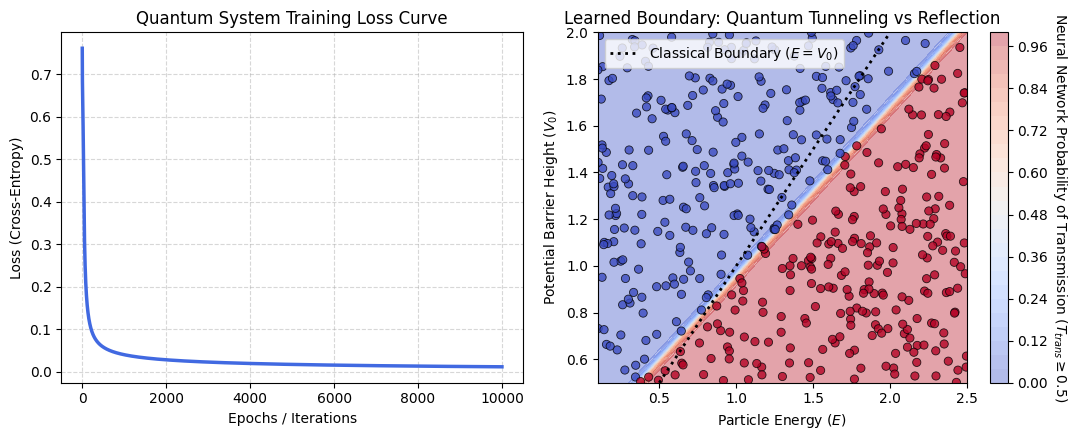

In [7]:
# QUANTUM SYSTEM DATA GENERATOR (The Physics Engine)
def generate_quantum_tunneling_data(num_samples=400):
    """
    Generates synthetic quantum mechanics data using the analytical solution
    to the 1D Schrödinger equation for a rectangular potential barrier.
    """
    np.random.seed(101)
    # Sample random particle energies (E) and barrier heights (V0)
    E = np.random.uniform(0.1, 2.5, num_samples)
    V0 = np.random.uniform(0.5, 2.0, num_samples)
    # Physical constants fixed for scaling (m = 1, h_bar = 1, L = 1.5)
    L = 1.5
    T_trans = np.zeros(num_samples)
    for i in range(num_samples):
        if E[i] < V0[i]:
            # Quantum tunneling regime
            kappa = np.sqrt(2.0 * (V0[i] - E[i]))
            T_trans[i] = 1.0 / (1.0 + (V0[i]**2 * np.sinh(kappa * L)**2) / (4.0 * E[i] * (V0[i] - E[i])))
        elif E[i] > V0[i]:
            # Over-barrier transmission regime (with quantum interference resonances)
            k = np.sqrt(2.0 * (E[i] - V0[i]))
            T_trans[i] = 1.0 / (1.0 + (V0[i]**2 * np.sin(k * L)**2) / (4.0 * E[i] * (E[i] - V0[i])))
        else:
            T_trans[i] = 1.0 / (1.0 + V0[i] * L**2 / 2.0)
    # Binary Classification Target: 1 for High Transmission, 0 for High Reflection
    Y = (T_trans >= 0.5).astype(float)
    # Package into matrix shape (features, samples) for our custom neural network
    X = np.vstack((E, V0))
    Y = Y.reshape(1, -1)
    return X, Y

# NEURAL NETWORK COMPONENTS
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)
def cross_entropy_cost(y_hat, y, epsilon=1e-15):
    y_hat = np.clip(y_hat, epsilon, 1.0 - epsilon)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

# CLASS MODULE OBJECT
class QuantumNetwork:
    def __init__(self, input_dim, hidden_dim, output_dim):
        np.random.seed(42)
        self.W1 = np.random.randn(hidden_dim, input_dim) * 0.5
        self.b1 = np.zeros((hidden_dim, 1))
        self.W2 = np.random.randn(output_dim, hidden_dim) * 0.5
        self.b2 = np.zeros((output_dim, 1))
    def forward(self, X):
        # Forward Pass Matrix Form
        self.z1 = np.dot(self.W1, X) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.W2, self.a1) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2
    def backward(self, X, Y):
        m = X.shape[1]
        # Backprop error deltas
        delta2 = (self.a2 - Y)
        delta1 = np.dot(self.W2.T, delta2) * sigmoid_derivative(self.z1)
        # Matrix gradients
        dW2 = np.dot(delta2, self.a1.T) / m
        db2 = np.sum(delta2, axis=1, keepdims=True) / m
        dW1 = np.dot(delta1, X.T) / m
        db1 = np.sum(delta1, axis=1, keepdims=True) / m
        return dW1, db1, dW2, db2
    def train(self, X, Y, epochs, beta):
        cost_history = []
        for epoch in range(epochs):
            y_hat = self.forward(X)
            cost = cross_entropy_cost(y_hat, Y)
            cost_history.append(cost)
            dW1, db1, dW2, db2 = self.backward(X, Y)
            # Gradient Descent Adjustments
            self.W1 -= beta * dW1
            self.b1 -= beta * db1
            self.W2 -= beta * dW2
            self.b2 -= beta * db2
            if (epoch + 1) % 2500 == 0 or epoch == 0:
                print(f"Epoch {epoch+1:5d}/{epochs} | System Cross-Entropy Loss: {cost:.6f}")
        return cost_history

# EXECUTION AND VISUALIZATION
# Generate 500 simulated quantum data tracking points
X_data, Y_data = generate_quantum_tunneling_data(num_samples=500)
# Instantiate a network: 2 inputs (E, V0) -> 8 Hidden Neurons -> 1 Output (Transmission state)
quantum_mlp = QuantumNetwork(input_dim=2, hidden_dim=8, output_dim=1)
print("--- Starting Backpropagation Training on Quantum Dataset ---")
losses = quantum_mlp.train(X_data, Y_data, epochs=10000, beta=0.8)
# Calculate final accuracy metrics
predictions = quantum_mlp.forward(X_data)
predicted_classes = (predictions >= 0.5).astype(float)
accuracy = np.mean(predicted_classes == Y_data) * 100
print(f"\nFinal Quantum Regime Classification Accuracy: {accuracy:.2f}%")
# Generate continuous spatial matrix plotting bounds
ee, vv = np.meshgrid(np.linspace(0.1, 2.5, 100), np.linspace(0.5, 2.0, 100))
grid_points = np.c_[ee.ravel(), vv.ravel()].T
grid_predictions = quantum_mlp.forward(grid_points).reshape(ee.shape)

# Create figures
plt.figure(figsize=(11, 4.5))
# Plot 1: Quantum training loss metric decay curve
plt.subplot(1, 2, 1)
plt.plot(losses, color='royalblue', linewidth=2.5)
plt.title("Quantum System Training Loss Curve")
plt.xlabel("Epochs / Iterations")
plt.ylabel("Loss (Cross-Entropy)")
plt.grid(True, linestyle='--', alpha=0.5)
# Plot 2: Learned quantum physical boundary
plt.subplot(1, 2, 2)
plt.contourf(ee, vv, grid_predictions, levels=30, cmap='coolwarm', alpha=0.4)
cbar = plt.colorbar()
cbar.set_label('Neural Network Probability of Transmission ($T_{trans} \geq 0.5$)', rotation=270, labelpad=15)

# Overlay real simulated experimental tokens
scatter = plt.scatter(X_data[0, :], X_data[1, :], c=Y_data.ravel(), cmap='coolwarm', s=35, edgecolor='black', alpha=0.8, linewidths=0.6)
# Overlay the structural classical line E = V0 for physical reference
plt.plot([0.5, 2.0], [0.5, 2.0], color='black', linestyle=':', linewidth=2, label='Classical Boundary ($E = V_0$)')
plt.title("Learned Boundary: Quantum Tunneling vs Reflection")
plt.xlabel("Particle Energy ($E$)")
plt.ylabel("Potential Barrier Height ($V_0$)")
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()
